## Multi-Layer Perceptron for Digit Classification

### Prepare Data

In [1]:
# Suppress all warnings
import warnings
warnings.filterwarnings('ignore')

# Import dependencies
import numpy as np
import pandas as pd
from tensorflow.python.keras.utils import np_utils
np.random.seed(10)

# Load data
train_data = pd.read_csv('Datasets/mnist_train.csv')
test_data = pd.read_csv('Datasets/mnist_test.csv')

X_train = train_data.iloc[:,1:].values.astype('float32')
y_train = train_data.iloc[:,0].values
X_test = test_data.iloc[:,1:].values.astype('float32')
y_test = test_data.iloc[:,0].values

In [2]:
X_train_normalized = X_train / 255
X_test_normalized = X_test / 255

In [3]:
y_test.shape

(10000,)

In [4]:
y_train_OneHot = np_utils.to_categorical(y_train)
y_test_OneHot = np_utils.to_categorical(y_test)

In [5]:
y_test_OneHot.shape

(10000, 10)

### Build Model

In [6]:
from tensorflow import keras
from keras.models import Sequential
from keras.layers import Dense

model = Sequential()
model.add(Dense(units=256, 
                input_dim=784, 
                kernel_initializer='normal', 
                activation='relu'))
model.add(Dense(units=10, 
                kernel_initializer='normal', 
                activation='softmax'))

In [7]:
print(model.summary())

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 256)                 │         200,960 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 10)                  │           2,570 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 203,530 (795.04 KB)

 Trainable params: 203,530 (795.04 KB)

 Non-trainable params: 0 (0.00 B)

None


### Train Model

In [8]:
model.compile(loss='categorical_crossentropy', 
              optimizer='adam', metrics=['accuracy'])

train_history = model.fit(x=X_train_normalized,
                          y=y_train_OneHot, validation_split=0.2, 
                          epochs=10, batch_size=200, verbose=2)

Epoch 1/10
240/240 - 2s - 7ms/step - accuracy: 0.8854 - loss: 0.4325 - val_accuracy: 0.9370 - val_loss: 0.2266
Epoch 2/10
240/240 - 1s - 3ms/step - accuracy: 0.9470 - loss: 0.1871 - val_accuracy: 0.9545 - val_loss: 0.1565
Epoch 3/10
240/240 - 1s - 3ms/step - accuracy: 0.9625 - loss: 0.1316 - val_accuracy: 0.9647 - val_loss: 0.1253
Epoch 4/10
240/240 - 1s - 3ms/step - accuracy: 0.9718 - loss: 0.1004 - val_accuracy: 0.9678 - val_loss: 0.1110
Epoch 5/10
240/240 - 1s - 3ms/step - accuracy: 0.9772 - loss: 0.0810 - val_accuracy: 0.9707 - val_loss: 0.0987
Epoch 6/10
240/240 - 1s - 3ms/step - accuracy: 0.9821 - loss: 0.0650 - val_accuracy: 0.9712 - val_loss: 0.0944
Epoch 7/10
240/240 - 1s - 3ms/step - accuracy: 0.9851 - loss: 0.0542 - val_accuracy: 0.9723 - val_loss: 0.0871
Epoch 8/10
240/240 - 1s - 3ms/step - accuracy: 0.9879 - loss: 0.0453 - val_accuracy: 0.9743 - val_loss: 0.0850
Epoch 9/10
240/240 - 1s - 3ms/step - accuracy: 0.9902 - loss: 0.0367 - val_accuracy: 0.9748 - val_loss: 0.0807
E

### Visualize Training Process

In [9]:
import matplotlib.pyplot as plt

def show_train_history(train_history,train,validation):
    plt.plot(train_history.history[train])
    plt.plot(train_history.history[validation])
    plt.title('Train History')
    plt.ylabel(train)
    plt.xlabel('Epoch')
    plt.legend(['train', 'validation'], loc='upper left')
    plt.show()

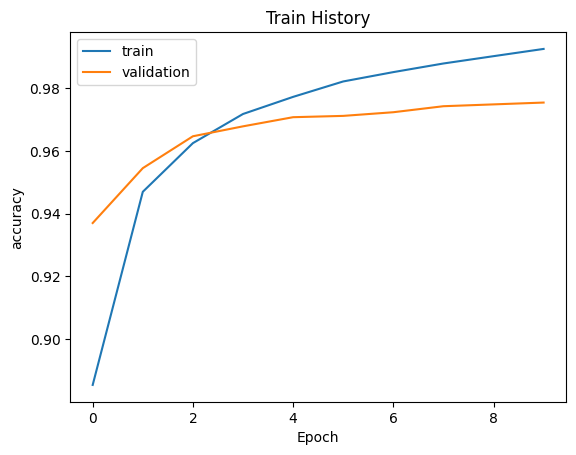

In [10]:
show_train_history(train_history, 'accuracy', 'val_accuracy')

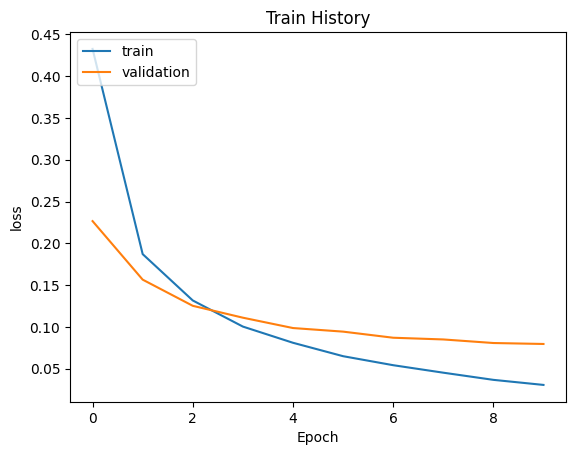

In [11]:
show_train_history(train_history,'loss','val_loss')

### Check Accuracy

In [12]:
scores = model.evaluate(X_test_normalized, y_test_OneHot)
print()
print('accuracy=', scores[1])

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9733 - loss: 0.0852

accuracy= 0.9771000146865845


### Prediction

In [13]:
# prediction = model.predict_classes(X_test)
predict_x = model.predict(X_test)
prediction = np.argmax(predict_x, axis=1)
prediction

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


array([7, 2, 1, ..., 4, 5, 6], dtype=int64)

In [14]:
prediction.shape

(10000,)

In [15]:
import matplotlib.pyplot as plt

def plot_images_labels_prediction(images, labels, prediction,
                                  idx, num=10):
    fig = plt.gcf()
    fig.set_size_inches(12, 14)
    if num>25: num=25 
    for i in range(0, num):
        ax=plt.subplot(5, 5, 1+i)
        ax.imshow(images[idx], cmap='binary')
        title= "label=" +str(labels[idx])
        if len(prediction)>0:
            title+=",predict="+str(prediction[idx]) 
            
        ax.set_title(title,fontsize=10) 
        ax.set_xticks([]);ax.set_yticks([])        
        idx+=1 
    plt.show()

In [16]:
X_test_image = X_test.reshape(len(X_test), 28, 28)

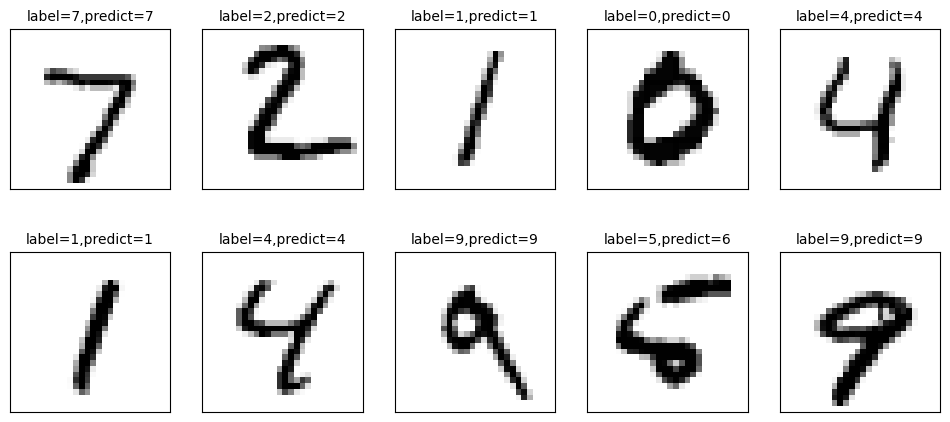

In [17]:
plot_images_labels_prediction(X_test_image, y_test,
                              prediction, idx=0)